In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Student Performance Analytics Engine")
print("Project Setup Successful!")

Student Performance Analytics Engine
Project Setup Successful!


In [2]:

import pandas as pd
import numpy as np

data = {
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Name": ["Rahul", "Aman", "Rohit", "Priya", "Sneha",
             "Ankit", "Neha", "Vikas", "Pooja", "Karan"],
    "Python": [85, 65, 42, 90, 78, 55, 95, 60, 72, 88],
    "Java": [80, 70, 45, 92, 75, 58, 90, 62, 76, 85],
    "DBMS": [88, 60, 40, 95, 80, 52, 92, 65, 70, 90],
    "Maths": [82, 68, 38, 88, 72, 50, 94, 58, 75, 86],
    "Attendance": [90, 75, 60, 95, 85, 65, 98, 70, 80, 92]
}

df = pd.DataFrame(data)

print("Student Dataset Created Successfully!")
display(df)


Student Dataset Created Successfully!


,Student_ID,Name,Python,Java,DBMS,Maths,Attendance
0,101,Rahul,85,80,88,82,90
1,102,Aman,65,70,60,68,75
2,103,Rohit,42,45,40,38,60
3,104,Priya,90,92,95,88,95
4,105,Sneha,78,75,80,72,85
5,106,Ankit,55,58,52,50,65
6,107,Neha,95,90,92,94,98
7,108,Vikas,60,62,65,58,70
8,109,Pooja,72,76,70,75,80
9,110,Karan,88,85,90,86,92


In [3]:
df.to_csv("students.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [4]:

# Student Performance Analysis

subjects = ["Python", "Java", "DBMS", "Maths"]

# Calculate total marks
df["Total"] = df[subjects].sum(axis=1)

# Calculate average marks
df["Average"] = df[subjects].mean(axis=1)

# Calculate percentage
df["Percentage"] = (df["Total"] / 400) * 100

# Grade calculation
def calculate_grade(percentage):
    if percentage >= 90:
        return "A+"
    elif percentage >= 80:
        return "A"
    elif percentage >= 70:
        return "B"
    elif percentage >= 60:
        return "C"
    elif percentage >= 50:
        return "D"
    else:
        return "F"

df["Grade"] = df["Percentage"].apply(calculate_grade)

# Pass or Fail calculation
def check_result(row):
    if all(row[subject] >= 35 for subject in subjects):
        return "Pass"
    else:
        return "Fail"

df["Result"] = df.apply(check_result, axis=1)

# Display final analysis
print("STUDENT PERFORMANCE ANALYSIS")
display(df)


STUDENT PERFORMANCE ANALYSIS


,Student_ID,Name,Python,Java,DBMS,Maths,Attendance,Total,Average,Percentage,Grade,Result
0,101,Rahul,85,80,88,82,90,335,83.75,83.75,A,Pass
1,102,Aman,65,70,60,68,75,263,65.75,65.75,C,Pass
2,103,Rohit,42,45,40,38,60,165,41.25,41.25,F,Pass
3,104,Priya,90,92,95,88,95,365,91.25,91.25,A+,Pass
4,105,Sneha,78,75,80,72,85,305,76.25,76.25,B,Pass
5,106,Ankit,55,58,52,50,65,215,53.75,53.75,D,Pass
6,107,Neha,95,90,92,94,98,371,92.75,92.75,A+,Pass
7,108,Vikas,60,62,65,58,70,245,61.25,61.25,C,Pass
8,109,Pooja,72,76,70,75,80,293,73.25,73.25,B,Pass
9,110,Karan,88,85,90,86,92,349,87.25,87.25,A,Pass


In [5]:

# Step 4: Student Performance Insights

print("===== STUDENT PERFORMANCE INSIGHTS =====")

# 1. Find Topper
topper = df.loc[df["Percentage"].idxmax()]

print("\n1. CLASS TOPPER")
print("Name:", topper["Name"])
print("Percentage:", topper["Percentage"])
print("Grade:", topper["Grade"])

# 2. Find Lowest Performing Student
lowest = df.loc[df["Percentage"].idxmin()]

print("\n2. LOWEST PERFORMING STUDENT")
print("Name:", lowest["Name"])
print("Percentage:", lowest["Percentage"])

# 3. Identify Weak Students
weak_students = df[df["Percentage"] < 50]

print("\n3. STUDENTS NEEDING IMPROVEMENT")
if len(weak_students) > 0:
    display(weak_students[["Name", "Percentage", "Grade"]])
else:
    print("No weak students found!")

# 4. Subject-wise Average
subject_average = df[subjects].mean()

print("\n4. SUBJECT-WISE CLASS AVERAGE")
display(subject_average.to_frame(name="Average Marks"))

# 5. Identify Weakest Subject
weak_subject = subject_average.idxmin()

print("\n5. WEAKEST SUBJECT")
print("Subject:", weak_subject)
print("Average Marks:", subject_average.min())

# 6. Overall Class Performance
class_average = df["Percentage"].mean()

print("\n6. OVERALL CLASS AVERAGE")
print(round(class_average, 2), "%")


===== STUDENT PERFORMANCE INSIGHTS =====

1. CLASS TOPPER
Name: Neha
Percentage: 92.75
Grade: A+

2. LOWEST PERFORMING STUDENT
Name: Rohit
Percentage: 41.25

3. STUDENTS NEEDING IMPROVEMENT


,Name,Percentage,Grade
2,Rohit,41.25,F



4. SUBJECT-WISE CLASS AVERAGE


,Average Marks
Python,73.0
Java,73.3
DBMS,73.2
Maths,71.1



5. WEAKEST SUBJECT
Subject: Maths
Average Marks: 71.1

6. OVERALL CLASS AVERAGE
72.65 %


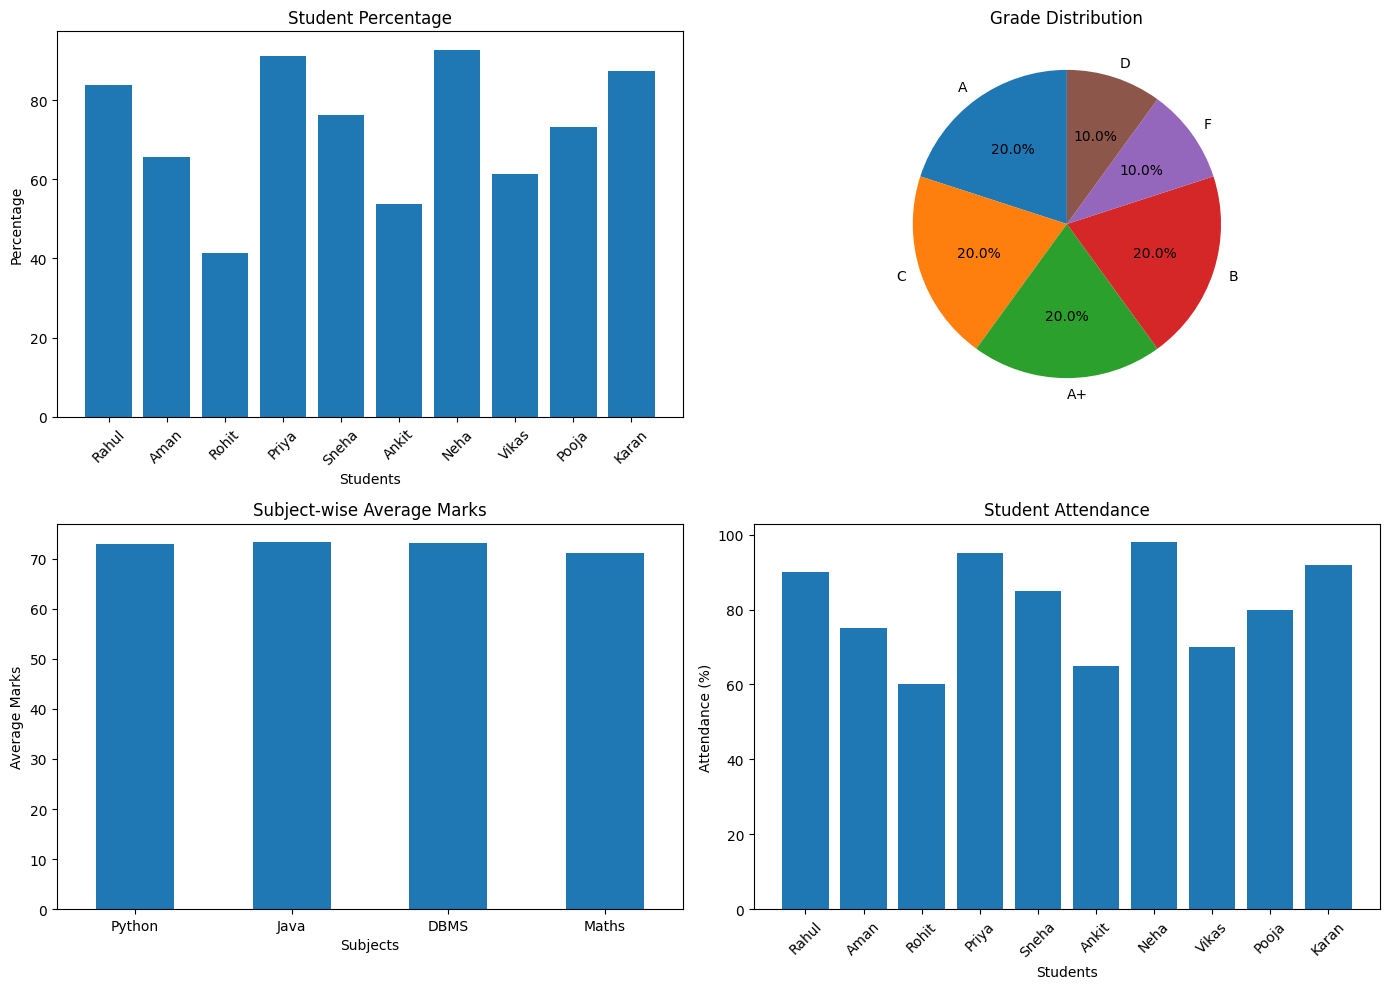

In [6]:

import matplotlib.pyplot as plt

# Create dashboard with 4 charts
plt.figure(figsize=(14, 10))

# 1. Student Percentage Bar Chart
plt.subplot(2, 2, 1)
plt.bar(df["Name"], df["Percentage"])
plt.title("Student Percentage")
plt.xlabel("Students")
plt.ylabel("Percentage")
plt.xticks(rotation=45)

# 2. Grade Distribution Pie Chart
plt.subplot(2, 2, 2)
grade_counts = df["Grade"].value_counts()
plt.pie(grade_counts, labels=grade_counts.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Grade Distribution")

# 3. Subject-wise Average Marks
plt.subplot(2, 2, 3)
subject_average.plot(kind="bar")
plt.title("Subject-wise Average Marks")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)

# 4. Attendance Chart
plt.subplot(2, 2, 4)
plt.bar(df["Name"], df["Attendance"])
plt.title("Student Attendance")
plt.xlabel("Students")
plt.ylabel("Attendance (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


<Figure size 1000x600 with 0 Axes>

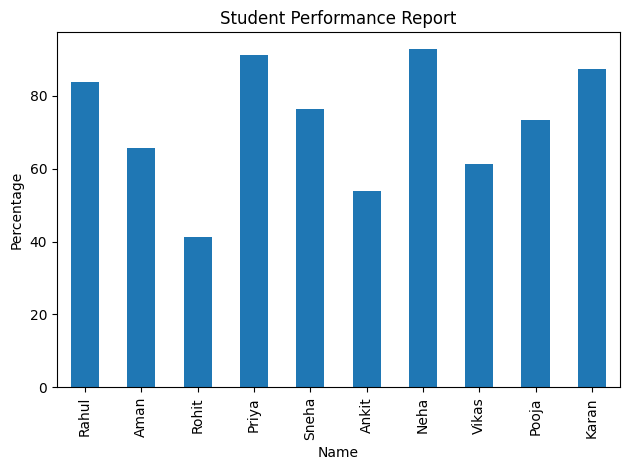

In [7]:
plt.figure(figsize=(10, 6))
df.plot(x="Name", y="Percentage", kind="bar",
        legend=False, title="Student Performance Report")

plt.ylabel("Percentage")
plt.tight_layout()
plt.savefig("student_performance_report.png")
plt.show()

In [8]:

%%writefile README.md

# Student Performance Analytics Engine

## About the Project
Student Performance Analytics Engine is a Python-based data analytics project that analyzes student academic performance.

## Features
- Student Dataset Management
- Total and Average Marks Calculation
- Percentage Calculation
- Automatic Grade Assignment
- Pass and Fail Detection
- Topper Identification
- Weak Student Identification
- Subject-wise Performance Analysis
- Student Attendance Analysis
- Data Visualization using Charts

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## Dataset
The project uses a sample dataset of 10 students with marks in:
- Python
- Java
- DBMS
- Maths
- Attendance

## How to Run
1. Download the project files.
2. Open the notebook in Google Colab.
3. Run all code cells.
4. View the student performance analysis and charts.

## Author
Student Project


Writing README.md


In [9]:

%%writefile requirements.txt
pandas
numpy
matplotlib


Writing requirements.txt


In [10]:
import shutil
from google.colab import files

shutil.make_archive("Student_Performance_Project", "zip", ".")

files.download("Student_Performance_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>